In [1]:
import pandas as pd
import numpy as np 

In [2]:
df = pd.read_csv("../datasets/complaints_preprocessed.csv")

print(df.info())
print(df.head())


<class 'pandas.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   complaint_id              8469 non-null   int64
 1   complaint_text            8469 non-null   str  
 2   category                  8469 non-null   str  
 3   priority                  8469 non-null   str  
 4   sentiment                 8469 non-null   str  
 5   emotion                   8469 non-null   str  
 6   department                8469 non-null   str  
 7   cleaned_text              8469 non-null   str  
 8   tokens                    8469 non-null   str  
 9   tokens_without_stopwords  8469 non-null   str  
 10  final_text                8469 non-null   str  
dtypes: int64(1), str(10)
memory usage: 727.9 KB
None
   complaint_id                                     complaint_text  \
0             1  Product setup. I'm having an issue with the {p...   
1             2  Peri

In [3]:
# %% Check missing values

print(df.isnull().sum())

# %% Check empty final text

print(
    "Empty texts:",
    df["final_text"].fillna("").str.strip().eq("").sum()
)

# %% Check target distributions
print(df["priority"].value_counts())
print(df["category"].value_counts())
print(df["sentiment"].value_counts())
print(df["emotion"].value_counts())

complaint_id                0
complaint_text              0
category                    0
priority                    0
sentiment                   0
emotion                     0
department                  0
cleaned_text                0
tokens                      0
tokens_without_stopwords    0
final_text                  0
dtype: int64
Empty texts: 0
priority
Medium      2192
Critical    2129
High        2085
Low         2063
Name: count, dtype: int64
category
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64
sentiment
Positive    5892
Negative    2186
Neutral      391
Name: count, dtype: int64
emotion
Other         5959
Satisfied     1192
Angry          750
Frustrated     410
Sad            158
Name: count, dtype: int64


In [4]:
X = df["final_text"]
y = df["category"]

In [5]:
# %% Train-test split

from sklearn.model_selection import train_test_split

X = df["final_text"].fillna("")
y = df["category"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 6775
Testing samples: 1694


In [6]:
# %% TF-IDF vectorization

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)# %% TF-IDF vectorization

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (6775, 5000)
Testing shape: (1694, 5000)
Training shape: (6775, 5000)
Testing shape: (1694, 5000)


In [7]:
# %% Import ML algorithms

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

models = {
    "Naive Bayes": MultinomialNB(),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

In [8]:
# %% Train models

for name, model in models.items():

    model.fit(X_train_tfidf, y_train)

    print(name, "trained successfully")

Naive Bayes trained successfully
Logistic Regression trained successfully
Linear SVM trained successfully


In [9]:
# %% Predictions

predictions = {}

for name, model in models.items():

    y_pred = model.predict(X_test_tfidf)

    predictions[name] = y_pred

In [10]:
# %% Model evaluation

from sklearn.metrics import classification_report

for name, y_pred in predictions.items():

    print("\nModel:", name)

    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )


Model: Naive Bayes
                      precision    recall  f1-score   support

     Billing inquiry       0.20      0.15      0.17       327
Cancellation request       0.20      0.21      0.21       339
     Product inquiry       0.22      0.21      0.22       328
      Refund request       0.20      0.22      0.21       351
     Technical issue       0.23      0.26      0.24       349

            accuracy                           0.21      1694
           macro avg       0.21      0.21      0.21      1694
        weighted avg       0.21      0.21      0.21      1694


Model: Logistic Regression
                      precision    recall  f1-score   support

     Billing inquiry       0.21      0.24      0.22       327
Cancellation request       0.19      0.19      0.19       339
     Product inquiry       0.21      0.25      0.23       328
      Refund request       0.20      0.17      0.18       351
     Technical issue       0.24      0.19      0.21       349

            accur

In [11]:
# %% Accuracy comparison

from sklearn.metrics import accuracy_score

results = []

for name, y_pred in predictions.items():

    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

results_df = pd.DataFrame(results)

print(
    results_df.sort_values(
        by="Accuracy",
        ascending=False
    )
)

                 Model  Accuracy
2           Linear SVM  0.212515
0          Naive Bayes  0.210153
1  Logistic Regression  0.208383


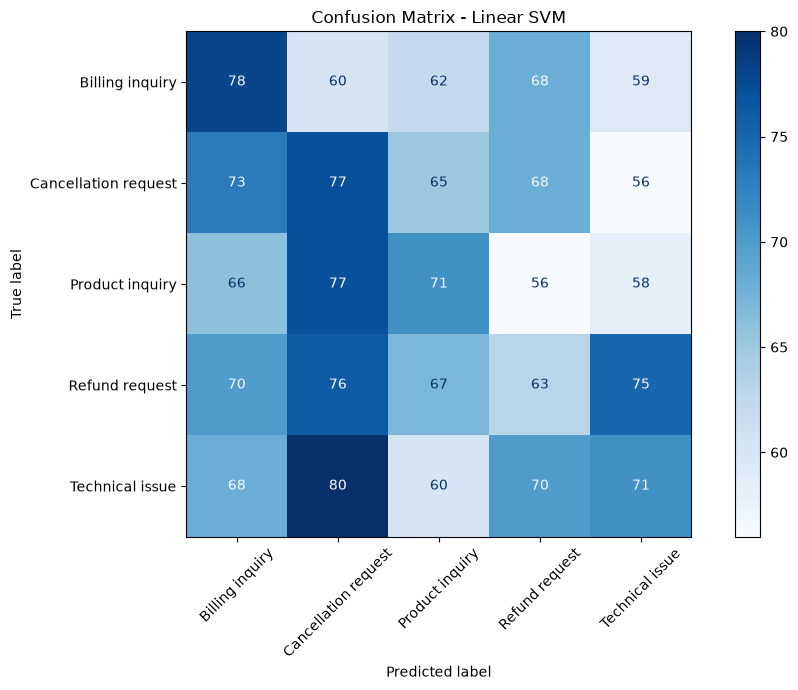

In [12]:
# %% Confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_model_name = results_df.sort_values(
    by="Accuracy",
    ascending=False
).iloc[0]["Model"]

best_model = models[best_model_name]

y_pred = best_model.predict(X_test_tfidf)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=best_model.classes_
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_
)

fig, ax = plt.subplots(figsize=(10, 7))

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

In [13]:
# %% Reusable classification function

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score
)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

def train_classifier(df, target_column):

    X = df["final_text"].fillna("")
    y = df[target_column]

    # Split dataset
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    models = {
        "Naive Bayes": MultinomialNB(),

        "Logistic Regression": LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ),

        "Linear SVM": LinearSVC(
            class_weight="balanced",
            random_state=42
        )
    }

    results = []
    trained_models = {}

    for name, model in models.items():

        pipeline = Pipeline([
            ("tfidf", TfidfVectorizer(
                max_features=5000,
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.95
            )),
            ("classifier", model)
        ])

        pipeline.fit(X_train, y_train)

        y_pred = pipeline.predict(X_test)

        accuracy = accuracy_score(y_test, y_pred)

        macro_f1 = f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        )

        results.append({
            "Model": name,
            "Accuracy": accuracy,
            "Macro F1": macro_f1
        })

        trained_models[name] = pipeline

        print(f"\n{name} - {target_column}")
        print(classification_report(
            y_test,
            y_pred,
            zero_division=0
        ))

    results_df = pd.DataFrame(results)

    print("\nModel comparison:")
    print(results_df.sort_values(
        by="Macro F1",
        ascending=False
    ))

    best_name = results_df.sort_values(
        by="Macro F1",
        ascending=False
    ).iloc[0]["Model"]

    best_pipeline = trained_models[best_name]

    print("\nBest model:", best_name)

    return best_pipeline, results_df

In [14]:
# %% Category classification

category_model, category_results = train_classifier(
    df,
    "category"
)


Naive Bayes - category
                      precision    recall  f1-score   support

     Billing inquiry       0.20      0.15      0.17       327
Cancellation request       0.20      0.21      0.21       339
     Product inquiry       0.22      0.21      0.22       328
      Refund request       0.20      0.22      0.21       351
     Technical issue       0.23      0.26      0.24       349

            accuracy                           0.21      1694
           macro avg       0.21      0.21      0.21      1694
        weighted avg       0.21      0.21      0.21      1694


Logistic Regression - category
                      precision    recall  f1-score   support

     Billing inquiry       0.21      0.24      0.22       327
Cancellation request       0.19      0.19      0.19       339
     Product inquiry       0.21      0.25      0.23       328
      Refund request       0.20      0.17      0.18       351
     Technical issue       0.24      0.19      0.21       349

         

In [15]:
# %% Priority classification

priority_model, priority_results = train_classifier(
    df,
    "priority"
)


Naive Bayes - priority
              precision    recall  f1-score   support

    Critical       0.23      0.25      0.24       426
        High       0.26      0.19      0.22       417
         Low       0.25      0.24      0.25       413
      Medium       0.28      0.33      0.30       438

    accuracy                           0.26      1694
   macro avg       0.26      0.26      0.25      1694
weighted avg       0.26      0.26      0.25      1694


Logistic Regression - priority
              precision    recall  f1-score   support

    Critical       0.23      0.23      0.23       426
        High       0.27      0.26      0.27       417
         Low       0.23      0.24      0.24       413
      Medium       0.25      0.24      0.25       438

    accuracy                           0.24      1694
   macro avg       0.24      0.24      0.24      1694
weighted avg       0.24      0.24      0.24      1694


Linear SVM - priority
              precision    recall  f1-score   suppo

In [19]:
# %% Sentiment classification

sentiment_model, sentiment_results = train_classifier(
    df,
    "sentiment"
)


Naive Bayes - sentiment
              precision    recall  f1-score   support

    Negative       0.73      0.66      0.69       437
     Neutral       0.00      0.00      0.00        78
    Positive       0.84      0.92      0.88      1179

    accuracy                           0.81      1694
   macro avg       0.52      0.53      0.52      1694
weighted avg       0.77      0.81      0.79      1694


Logistic Regression - sentiment
              precision    recall  f1-score   support

    Negative       0.75      0.79      0.77       437
     Neutral       0.21      0.55      0.31        78
    Positive       0.95      0.83      0.89      1179

    accuracy                           0.81      1694
   macro avg       0.64      0.73      0.66      1694
weighted avg       0.87      0.81      0.83      1694


Linear SVM - sentiment
              precision    recall  f1-score   support

    Negative       0.79      0.84      0.81       437
     Neutral       0.29      0.26      0.27    

In [20]:
# %% Sentiment classification

sentiment_model, sentiment_results = train_classifier(
    df,
    "sentiment"
)


Naive Bayes - sentiment
              precision    recall  f1-score   support

    Negative       0.73      0.66      0.69       437
     Neutral       0.00      0.00      0.00        78
    Positive       0.84      0.92      0.88      1179

    accuracy                           0.81      1694
   macro avg       0.52      0.53      0.52      1694
weighted avg       0.77      0.81      0.79      1694


Logistic Regression - sentiment
              precision    recall  f1-score   support

    Negative       0.75      0.79      0.77       437
     Neutral       0.21      0.55      0.31        78
    Positive       0.95      0.83      0.89      1179

    accuracy                           0.81      1694
   macro avg       0.64      0.73      0.66      1694
weighted avg       0.87      0.81      0.83      1694


Linear SVM - sentiment
              precision    recall  f1-score   support

    Negative       0.79      0.84      0.81       437
     Neutral       0.29      0.26      0.27    

In [21]:
# %% Emotion classification

emotion_model, emotion_results = train_classifier(
    df,
    "emotion"
)


Naive Bayes - emotion
              precision    recall  f1-score   support

       Angry       0.93      0.85      0.89       150
  Frustrated       0.85      0.88      0.86        82
       Other       0.84      1.00      0.91      1192
         Sad       0.00      0.00      0.00        32
   Satisfied       0.77      0.20      0.31       238

    accuracy                           0.85      1694
   macro avg       0.68      0.58      0.60      1694
weighted avg       0.82      0.85      0.81      1694


Logistic Regression - emotion
              precision    recall  f1-score   support

       Angry       0.94      0.89      0.92       150
  Frustrated       0.88      0.95      0.91        82
       Other       0.97      1.00      0.99      1192
         Sad       0.94      0.91      0.92        32
   Satisfied       0.98      0.85      0.91       238

    accuracy                           0.96      1694
   macro avg       0.94      0.92      0.93      1694
weighted avg       0.96

In [22]:
# %% Save models

import joblib
import os

os.makedirs("artifacts", exist_ok=True)

joblib.dump(
    category_model,
    "artifacts/category_model.pkl"
)

joblib.dump(
    priority_model,
    "artifacts/priority_model.pkl"
)

joblib.dump(
    sentiment_model,
    "artifacts/sentiment_model.pkl"
)

joblib.dump(
    emotion_model,
    "artifacts/emotion_model.pkl"
)


print("All models saved successfully!")

All models saved successfully!


In [24]:
# %% Import libraries

import pandas as pd
import numpy as np

# %% Load dataset

df = pd.read_csv(
    "../datasets/complaints_preprocessed.csv"
)

print(df.head())

   complaint_id                                     complaint_text  \
0             1  Product setup. I'm having an issue with the {p...   
1             2  Peripheral compatibility. I'm having an issue ...   
2             3  Network problem. I'm facing a problem with my ...   
3             4  Account access. I'm having an issue with the {...   
4             5  Data loss. I'm having an issue with the {produ...   

          category  priority sentiment    emotion         department  \
0  Technical issue  Critical  Positive  Satisfied  Technical Support   
1  Technical issue  Critical  Positive      Other  Technical Support   
2  Technical issue       Low  Positive      Other  Technical Support   
3  Billing inquiry       Low  Positive  Satisfied            Billing   
4  Billing inquiry       Low  Negative      Other            Billing   

                                        cleaned_text  \
0  product setup i m having an issue with the pro...   
1  peripheral compatibility i m ha

In [25]:
# %% Load sentence transformer

from sentence_transformers import SentenceTransformer

model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [26]:
# %% Generate embeddings

complaints = df["final_text"].fillna("").tolist()

embeddings = model.encode(
    complaints,
    show_progress_bar=True,
    convert_to_numpy=True
)

print("Embedding shape:", embeddings.shape)

Batches:   0%|          | 0/265 [00:00<?, ?it/s]

Embedding shape: (8469, 384)


In [27]:
# %% Calculate cosine similarity

from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix = cosine_similarity(
    embeddings
)

print(similarity_matrix.shape)

(8469, 8469)


In [28]:
# %% Find similar complaints

def find_similar_complaints(query, top_n=5):

    query_embedding = model.encode(
        [query],
        convert_to_numpy=True
    )

    scores = cosine_similarity(
        query_embedding,
        embeddings
    )[0]

    top_indices = np.argsort(scores)[::-1]

    results = []

    for idx in top_indices:

        if query.strip().lower() == str(
            df.iloc[idx]["complaint_text"]
        ).strip().lower():
            continue

        results.append({
            "complaint_text": df.iloc[idx]["complaint_text"],
            "category": df.iloc[idx]["category"],
            "priority": df.iloc[idx]["priority"],
            "sentiment": df.iloc[idx]["sentiment"],
            "emotion": df.iloc[idx]["emotion"],
            "similarity_score": round(
                float(scores[idx]), 3
            )
        })

        if len(results) == top_n:
            break

    return pd.DataFrame(results)

In [29]:
# %% Test semantic similarity

new_complaint = (
    "My payment was successful but I did not receive my order."
)

similar_complaints = find_similar_complaints(
    new_complaint,
    top_n=5
)

print(similar_complaints)

                                      complaint_text              category  \
0  Payment issue. I'm having an issue with the {p...       Product inquiry   
1  Payment issue. I'm having an issue with the {p...       Billing inquiry   
2  Payment issue. I'm having an issue with the {p...       Technical issue   
3  Payment issue. I'm having an issue with the {p...       Product inquiry   
4  Payment issue. I'm having an issue with the {p...  Cancellation request   

  priority sentiment    emotion  similarity_score  
0   Medium  Positive      Other             0.631  
1   Medium  Positive  Satisfied             0.627  
2     High  Positive  Satisfied             0.624  
3     High  Positive  Satisfied             0.612  
4     High  Positive  Satisfied             0.608  


In [30]:
joblib.dump(
    embeddings,
    "artifacts/complaint_embeddings.pkl"
)

joblib.dump(
    df,
    "artifacts/complaints_data.pkl"
)

['artifacts/complaints_data.pkl']